# 07 - Scorecard di credito (Weight of Evidence / Information Value)

**Progetto:** Credit Risk Scorecard - *Give Me Some Credit*

Costruiamo una scorecard di credito con la metodologia classica **WOE/IV**, lo standard storico
del credit scoring bancario (precede l'uso di modelli ad albero/boosting, ma resta lo standard per
gli score card regolamentari per la sua trasparenza totale: ogni punto è tracciabile a una fascia
di una variabile).

Passi: binning delle variabili (quantili + verifica di monotonia per le continue, raggruppamenti
per le discrete) → calcolo di Weight of Evidence e Information Value per fascia e per variabile →
selezione delle variabili con IV ≥ 0,1 → regressione logistica con encoding WOE → conversione dei
coefficienti in punti scorecard → esportazione.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

COLOR_SEQ = '#2a78d6'
COLOR_CRITICAL = '#d03b3b'
GRID_COLOR = '#e1e0d9'
TEXT_COLOR = '#0b0b0b'
MUTED_COLOR = '#898781'

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': GRID_COLOR,
    'axes.grid': True,
    'grid.color': GRID_COLOR,
    'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'text.color': TEXT_COLOR,
    'axes.labelcolor': TEXT_COLOR,
    'xtick.color': MUTED_COLOR,
    'ytick.color': MUTED_COLOR,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

## 1. Caricamento dataset e definizione di WOE/IV

Convenzione standard (Siddiqi, *Credit Risk Scorecards*): **"buono" = non insolvente
(`SeriousDlqin2yrs=0`)**, **"cattivo" = insolvente (`=1`)**. Per ciascuna fascia di una variabile:

$$WOE = \ln\left(\frac{\%\ buoni}{\%\ cattivi}\right) \qquad IV_{fascia} = (\%\ buoni - \%\ cattivi) \times WOE \qquad IV_{variabile} = \sum_{fasce} IV_{fascia}$$

WOE positivo = fascia con più buoni della media (meno rischiosa); negativo = più cattivi della
media (più rischiosa). L'IV totale per variabile si legge con la scala standard di settore:

| IV | Potere predittivo |
|---|---|
| < 0.02 | non predittiva |
| 0.02 - 0.1 | debole |
| 0.1 - 0.3 | media |
| 0.3 - 0.5 | forte |
| > 0.5 | sospetta (troppo bella per essere vera) |

In [2]:
PROJECT_ROOT = Path.cwd().resolve().parents[1]
CLEAN_PATH = PROJECT_ROOT / 'data' / 'processed' / 'cs-training-clean.csv'

df = pd.read_csv(CLEAN_PATH, index_col=0)
TARGET = 'SeriousDlqin2yrs'

FEATURES = [
    'RevolvingUtilizationOfUnsecuredLines',
    'age',
    'NumberOfTime30-59DaysPastDueNotWorse',
    'DebtRatio',
    'MonthlyIncome',
    'NumberOfOpenCreditLinesAndLoans',
    'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents',
    'MonthlyIncome_mancante',
    'NumberOfDependents_mancante',
]
print(f"Righe: {len(df):,}  |  Variabili candidate: {len(FEATURES)}")

Righe: 149,999  |  Variabili candidate: 12


In [3]:
def woe_table(bins, target):
    # Tabella WOE/IV per fascia, data una Serie di etichette di fascia e il target 0/1.
    tmp = pd.DataFrame({'bin': bins, 'target': target})
    grp = tmp.groupby('bin', observed=True)['target'].agg(n='count', n_bad='sum')
    grp['n_good'] = grp['n'] - grp['n_bad']
    total_good = grp['n_good'].sum()
    total_bad = grp['n_bad'].sum()
    grp['pct_good'] = grp['n_good'] / total_good
    grp['pct_bad'] = grp['n_bad'] / total_bad
    # piccola correzione di continuita': evita ln(0)/divisioni per 0 in fasce con 0 buoni o 0 cattivi
    eps = 1e-6
    grp['WOE'] = np.log((grp['pct_good'] + eps) / (grp['pct_bad'] + eps))
    grp['IV_contrib'] = (grp['pct_good'] - grp['pct_bad']) * grp['WOE']
    return grp


def is_monotonic(values):
    inc = all(values[i] <= values[i + 1] for i in range(len(values) - 1))
    dec = all(values[i] >= values[i + 1] for i in range(len(values) - 1))
    return inc or dec


def quantile_bin_monotonic(series, target, max_bins=10):
    # Binning per quantili; unisce le fasce adiacenti piu' simili finche' il WOE
    # non e' monotono attraverso le fasce (o restano solo 2 fasce, il minimo utile).
    edges = np.unique(np.quantile(series, np.linspace(0, 1, max_bins + 1)))
    while True:
        bins = pd.cut(series, bins=edges, include_lowest=True, duplicates='drop')
        t = woe_table(bins, target)
        woe = t['WOE'].values
        if is_monotonic(woe) or len(woe) <= 2:
            break
        merge_pos = np.argmin(np.abs(np.diff(woe)))
        edges = np.delete(edges, merge_pos + 1)
    return edges, t


def classify_iv(iv):
    if iv < 0.02:
        return 'non predittiva'
    if iv < 0.1:
        return 'debole'
    if iv < 0.3:
        return 'media'
    if iv < 0.5:
        return 'forte'
    return 'sospetta'

## 2. Binning delle variabili continue

`RevolvingUtilizationOfUnsecuredLines`, `age`, `DebtRatio`, `MonthlyIncome`: partiamo da 10 fasce
per quantili e uniamo le fasce adiacenti finché il WOE non è monotono attraverso l'intero range
della variabile (requisito standard per una scorecard: un cliente più "estremo" in una direzione
non deve mai risultare meno rischioso di uno meno estremo nella stessa direzione).

In [4]:
CONTINUOUS_VARS = ['RevolvingUtilizationOfUnsecuredLines', 'age', 'DebtRatio', 'MonthlyIncome']

binning_results = {}

for var in CONTINUOUS_VARS:
    edges, t = quantile_bin_monotonic(df[var], df[TARGET])
    iv = t['IV_contrib'].sum()
    binning_results[var] = {'type': 'continuous', 'edges': edges, 'woe_table': t, 'iv': iv}
    print(f"=== {var}: {len(t)} fasce finali (da 10 iniziali), IV = {iv:.4f} ===")
    display(t[['n', 'n_bad', 'pct_good', 'pct_bad', 'WOE', 'IV_contrib']].round(4))

=== RevolvingUtilizationOfUnsecuredLines: 4 fasce finali (da 10 iniziali), IV = 1.0667 ===


,n,n_bad,pct_good,pct_bad,WOE,IV_contrib
bin,,,,,,
"(-0.001, 0.154]",75000,1435,0.5256,0.1431,1.3007,0.4974
"(0.154, 0.445]",29999,1308,0.2050,0.1305,0.4518,0.0337
"(0.445, 0.699]",15000,1320,0.0977,0.1317,-0.2980,0.0101
"(0.699, 1.093]",30000,5963,0.1717,0.5948,-1.2422,0.5255


=== age: 10 fasce finali (da 10 iniziali), IV = 0.2592 ===


,n,n_bad,pct_good,pct_bad,WOE,IV_contrib
bin,,,,,,
"(20.999, 33.0]",17084,1940,0.1082,0.1935,-0.5813,0.0496
"(33.0, 39.0]",14919,1430,0.0964,0.1426,-0.3921,0.0181
"(39.0, 44.0]",15799,1365,0.1031,0.1361,-0.2778,0.0092
"(44.0, 48.0]",14741,1200,0.0967,0.1197,-0.2129,0.0049
"(48.0, 52.0]",14826,1142,0.0978,0.1139,-0.1528,0.0025
"(52.0, 56.0]",14214,935,0.0949,0.0933,0.0171,0.0000
"(56.0, 61.0]",16878,839,0.1146,0.0837,0.3143,0.0097
"(61.0, 65.0]",12939,485,0.0890,0.0484,0.6094,0.0247
"(65.0, 72.0]",14258,380,0.0991,0.0379,0.9616,0.0589


=== DebtRatio: 2 fasce finali (da 10 iniziali), IV = 0.0091 ===


,n,n_bad,pct_good,pct_bad,WOE,IV_contrib
bin,,,,,,
"(-0.001, 4.0]",120108,8373,0.7983,0.8351,-0.0452,0.0017
"(4.0, 4979.08]",29891,1653,0.2017,0.1649,0.2018,0.0074


=== MonthlyIncome: 2 fasce finali (da 10 iniziali), IV = 0.0661 ===


,n,n_bad,pct_good,pct_bad,WOE,IV_contrib
bin,,,,,,
"(-0.001, 4166.0]",45377,4180,0.2943,0.4169,-0.3482,0.0427
"(4166.0, 3008750.0]",104622,5846,0.7057,0.5831,0.1908,0.0234


## 3. Binning delle variabili discrete

Per le colonne di conteggio (ritardi di pagamento, prestiti, dipendenti), fortemente
zero-inflazionate (la maggior parte dei clienti ha valore 0), usiamo piccoli raggruppamenti invece
dei quantili — ogni valore raro nella coda avrebbe altrimenti una fascia a sé, con stime di WOE
instabili su pochissime osservazioni. Le due variabili flag (già binarie) restano 0/1 senza
ulteriore binning.

In [5]:
def bin_low_count(x, cap):
    return str(int(x)) if x < cap else f'{cap}+'

def bin_open_credit_lines(x):
    if x <= 4:
        return '0-4'
    elif x <= 9:
        return '5-9'
    elif x <= 14:
        return '10-14'
    elif x <= 19:
        return '15-19'
    elif x <= 24:
        return '20-24'
    return '25+'

LOW_COUNT_VARS = {
    'NumberOfTime30-59DaysPastDueNotWorse': 3,
    'NumberOfTime60-89DaysPastDueNotWorse': 3,
    'NumberOfTimes90DaysLate': 3,
    'NumberRealEstateLoansOrLines': 3,
    'NumberOfDependents': 4,
}
BINARY_VARS = ['MonthlyIncome_mancante', 'NumberOfDependents_mancante']

for var, cap in LOW_COUNT_VARS.items():
    bins = df[var].apply(lambda x, cap=cap: bin_low_count(x, cap))
    t = woe_table(bins, df[TARGET])
    iv = t['IV_contrib'].sum()
    binning_results[var] = {'type': 'discrete', 'bin_func': (lambda x, cap=cap: bin_low_count(x, cap)), 'woe_table': t, 'iv': iv}
    print(f"=== {var}: IV = {iv:.4f} ===")
    display(t[['n', 'n_bad', 'pct_good', 'pct_bad', 'WOE', 'IV_contrib']].round(4))

bins = df['NumberOfOpenCreditLinesAndLoans'].apply(bin_open_credit_lines)
t = woe_table(bins, df[TARGET])
iv = t['IV_contrib'].sum()
binning_results['NumberOfOpenCreditLinesAndLoans'] = {'type': 'discrete', 'bin_func': bin_open_credit_lines, 'woe_table': t, 'iv': iv}
print(f"=== NumberOfOpenCreditLinesAndLoans: IV = {iv:.4f} ===")
display(t[['n', 'n_bad', 'pct_good', 'pct_bad', 'WOE', 'IV_contrib']].round(4))

for var in BINARY_VARS:
    bins = df[var].astype(str)
    t = woe_table(bins, df[TARGET])
    iv = t['IV_contrib'].sum()
    binning_results[var] = {'type': 'discrete', 'bin_func': (lambda x: str(int(x))), 'woe_table': t, 'iv': iv}
    print(f"=== {var}: IV = {iv:.4f} ===")
    display(t[['n', 'n_bad', 'pct_good', 'pct_bad', 'WOE', 'IV_contrib']].round(4))

=== NumberOfTime30-59DaysPastDueNotWorse: IV = 0.7552 ===


,n,n_bad,pct_good,pct_bad,WOE,IV_contrib
bin,,,,,,
0,126018,5041,0.8643,0.5028,0.5417,0.1958
1,16032,2409,0.0973,0.2403,-0.9037,0.1292
2,4598,1219,0.0241,0.1216,-1.6167,0.1575
3+,3351,1357,0.0142,0.1353,-2.2513,0.2726


=== NumberOfTime60-89DaysPastDueNotWorse: IV = 0.6000 ===


,n,n_bad,pct_good,pct_bad,WOE,IV_contrib
bin,,,,,,
0,142395,7256,0.9655,0.7237,0.2882,0.0697
1,5731,1777,0.0282,0.1772,-1.8364,0.2736
2,1118,561,0.0040,0.0560,-2.6432,0.1374
3+,755,432,0.0023,0.0431,-2.9266,0.1193


=== NumberOfTimes90DaysLate: IV = 0.8774 ===


,n,n_bad,pct_good,pct_bad,WOE,IV_contrib
bin,,,,,,
0,141661,6554,0.9652,0.6537,0.3897,0.1214
1,5243,1765,0.0248,0.1760,-1.9579,0.2960
2,1555,776,0.0056,0.0774,-2.6322,0.1891
3+,1540,931,0.0044,0.0929,-3.0605,0.2709


... (6 outputs left out)

=== MonthlyIncome_mancante: IV = 0.0077 ===


,n,n_bad,pct_good,pct_bad,WOE,IV_contrib
bin,,,,,,
0,120268,8357,0.7995,0.8335,-0.0417,0.0014
1,29731,1669,0.2005,0.1665,0.1859,0.0063


=== NumberOfDependents_mancante: IV = 0.0037 ===


,n,n_bad,pct_good,pct_bad,WOE,IV_contrib
bin,,,,,,
0,146075,9847,0.9732,0.9821,-0.0091,0.0001
1,3924,179,0.0268,0.0179,0.4045,0.0036


## 4. Riepilogo Information Value per variabile

In [6]:
iv_summary = pd.DataFrame([
    {'variabile': var, 'IV': res['iv'], 'n_fasce': len(res['woe_table']), 'classificazione': classify_iv(res['iv'])}
    for var, res in binning_results.items()
]).sort_values('IV', ascending=False).reset_index(drop=True)

iv_summary.round(4)

,variabile,IV,n_fasce,classificazione
0,RevolvingUtilizationOfUnsecuredLines,1.0667,4,sospetta
1,NumberOfTimes90DaysLate,0.8774,4,sospetta
2,NumberOfTime30-59DaysPastDueNotWorse,0.7552,4,sospetta
3,NumberOfTime60-89DaysPastDueNotWorse,0.6000,4,sospetta
4,age,0.2592,10,media
5,MonthlyIncome,0.0661,2,debole
6,NumberRealEstateLoansOrLines,0.0554,4,debole
7,NumberOfOpenCreditLinesAndLoans,0.0487,6,debole
8,NumberOfDependents,0.0344,5,debole
9,DebtRatio,0.0091,2,non predittiva


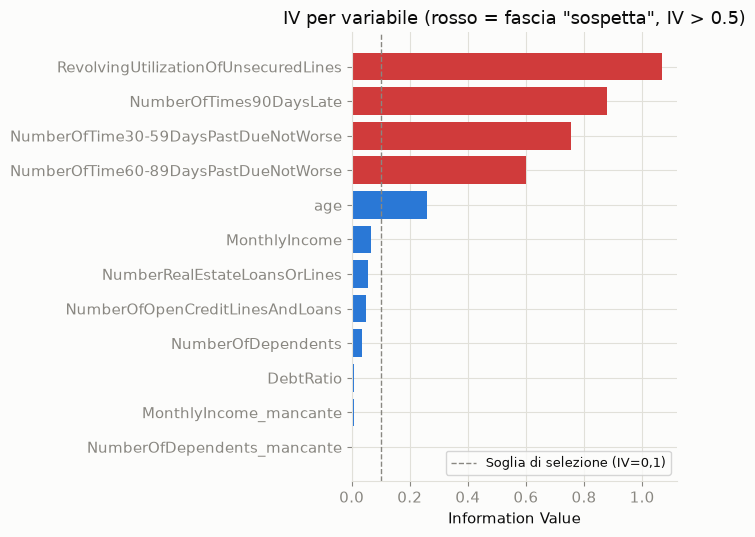

In [7]:
fig, ax = plt.subplots(figsize=(7, 5.5))
colors = [COLOR_CRITICAL if v >= 0.5 else COLOR_SEQ for v in iv_summary['IV']]
ax.barh(iv_summary['variabile'], iv_summary['IV'], color=colors)
ax.axvline(0.1, color=MUTED_COLOR, linestyle='--', linewidth=1, label='Soglia di selezione (IV=0,1)')
ax.invert_yaxis()
ax.set_xlabel('Information Value')
ax.set_title('IV per variabile (rosso = fascia "sospetta", IV > 0.5)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

**Quattro variabili ricadono nella fascia "sospetta" (IV > 0,5)**:
`RevolvingUtilizationOfUnsecuredLines` (1,07) e le tre colonne di ritardo pagamenti (0,60-0,88).
In una scorecard bancaria reale, un IV così alto è di norma un campanello d'allarme che spinge a
verificare se la variabile sia in qualche modo una proxy quasi diretta del target (data leakage) o
se il risultato sia un artefatto del binning stesso (che "guarda" il target nello scegliere le
fasce, quindi tende sempre a gonfiare leggermente l'IV apparente).

La concordanza con i notebook precedenti (test d'ipotesi del `02`, odds ratio e feature
importance del `03`/`04`, valori SHAP del `05`) conferma che queste sono le variabili più
predittive del dataset, ma **non esclude il leakage**: una variabile che anticipa il target
risulterebbe la migliore per qualunque metodo. Il punto da verificare è la finestra temporale.
Per i ritardi a 30-59 e 60-89 giorni la documentazione della fonte indica una finestra di due anni;
per `NumberOfTimes90DaysLate` non ne indica nessuna, e il target è definito proprio come 90+ giorni
di ritardo. Non è chiaro se quel conteggio preceda il periodo del target, quindi il suo IV (0,88) va
letto con cautela. `RevolvingUtilizationOfUnsecuredLines` misura invece l'utilizzo del fido, un
comportamento diverso dall'insolvenza. Manteniamo le quattro variabili nella scorecard, ma in un
contesto bancario reale andrebbero verificate prima dell'uso, a partire da `NumberOfTimes90DaysLate`.

**`age`** è nella fascia "media" (0,26). Tutte le altre variabili sono deboli o non predittive,
inclusa **`DebtRatio`** (0,009, non predittiva) — coerente con quanto già osservato nei notebook
`02` e `03`/`04`: nonostante sia la variabile più asimmetrica del dataset, il suo contenuto
informativo per la scorecard è quasi nullo.

## 5. Selezione delle variabili per la scorecard (IV ≥ 0,1)

In [8]:
SELECTED_VARS = iv_summary[iv_summary['IV'] >= 0.1]['variabile'].tolist()
print("Variabili selezionate per la scorecard finale:")
for v in SELECTED_VARS:
    print(f"  - {v} (IV = {binning_results[v]['iv']:.4f})")

Variabili selezionate per la scorecard finale:
  - RevolvingUtilizationOfUnsecuredLines (IV = 1.0667)
  - NumberOfTimes90DaysLate (IV = 0.8774)
  - NumberOfTime30-59DaysPastDueNotWorse (IV = 0.7552)
  - NumberOfTime60-89DaysPastDueNotWorse (IV = 0.6000)
  - age (IV = 0.2592)


## 6. Regressione logistica con WOE encoding

Sostituiamo il valore grezzo di ciascuna variabile selezionata con il WOE della fascia a cui
appartiene, poi alleniamo la regressione logistica sui valori WOE. Costruiamo la scorecard
sull'intero dataset pulito (non su uno split train/test): l'obiettivo qui è produrre uno strumento
di scoring finale, non validare ulteriormente le prestazioni del modello — già approfondite nei
notebook `03` e `04`.

In [9]:
import statsmodels.api as sm

X_woe = pd.DataFrame(index=df.index)
for var in SELECTED_VARS:
    res = binning_results[var]
    if res['type'] == 'continuous':
        bins = pd.cut(df[var], bins=res['edges'], include_lowest=True)
    else:
        bins = df[var].apply(res['bin_func'])
    X_woe[var] = bins.map(res['woe_table']['WOE']).astype(float)

assert X_woe.isnull().sum().sum() == 0, "valori mancanti nell'encoding WOE"

X_woe_c = sm.add_constant(X_woe)
scorecard_model = sm.Logit(df[TARGET], X_woe_c).fit(disp=0)
scorecard_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:       SeriousDlqin2yrs   No. Observations:               149999
Model:                          Logit   Df Residuals:                   149993
Method:                           MLE   Df Model:                            5
Date:                Sun, 13 Sep 2026   Pseudo R-squ.:                  0.2460
Time:                        19:48:25   Log-Likelihood:                -27753.
converged:                       True   LL-Null:                       -36808.
Covariance Type:            nonrobust   LLR p-value:                     0.000
========================================================================================================
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
const                                   -2.6000      0.013   -207.581      0.000      -2.625      -2.575
RevolvingUtilizationOfUnsecuredLines    -0.6393      0.012    -52.144      0.000      -0.663      -0.615
NumberOfTimes90DaysLate                 -0.5320      0.011    -47.491      0.000      -0.554      -0.510
NumberOfTime30-59DaysPastDueNotWorse    -0.5260      0.013    -41.331      0.000      -0.551      -0.501
NumberOfTime60-89DaysPastDueNotWorse    -0.3750      0.014    -26.534      0.000      -0.403      -0.347
age                                     -0.4607      0.026    -17.800      0.000      -0.511      -0.410
========================================================================================================
"""

Tutti i coefficienti sono **negativi**: non è un problema, è l'atteso per costruzione. Il WOE è già
definito in modo che un valore alto significhi "meno rischioso"; un coefficiente negativo davanti a
un WOE alto abbassa la probabilità stimata di insolvenza — esattamente il comportamento voluto. La
conversione in punti (sezione successiva) gestisce correttamente questo segno.

## 7. Conversione in punti scorecard

Parametri di scala standard: punteggio base **600** a odds (buoni:cattivi) **50:1**, **PDO = 20**
(ogni 20 punti raddoppiano gli odds di essere un buon cliente).

$$Factor = \frac{PDO}{\ln 2} \qquad Offset = 600 - Factor \times \ln(50)$$

Punti per fascia: $Punti = -Factor \times \beta_{variabile} \times WOE_{fascia}$ (il segno meno
compensa il coefficiente negativo, così che un WOE alto — fascia più sicura — dia più punti).
Punti base (dall'intercetta): $Offset - Factor \times \beta_0$.

In [10]:
PDO = 20
BASE_SCORE = 600
BASE_ODDS = 50

FACTOR = PDO / np.log(2)
OFFSET = BASE_SCORE - FACTOR * np.log(BASE_ODDS)
BASE_POINTS = OFFSET - FACTOR * scorecard_model.params['const']

print(f"Factor = {FACTOR:.4f}   Offset = {OFFSET:.4f}")
print(f"Punti base (intercetta): {BASE_POINTS:.2f}")

Factor = 28.8539   Offset = 487.1229
Punti base (intercetta): 562.14


In [11]:
scorecard_rows = [{'Variabile': 'Punteggio Base', 'Fascia': '(intercetta)', 'WOE': np.nan, 'Punti': round(BASE_POINTS, 1)}]

for var in SELECTED_VARS:
    beta = scorecard_model.params[var]
    woe_series = binning_results[var]['woe_table']['WOE']
    for bin_label, woe_val in woe_series.items():
        points = -FACTOR * beta * woe_val
        scorecard_rows.append({
            'Variabile': var,
            'Fascia': str(bin_label),
            'WOE': round(woe_val, 4),
            'Punti': round(points, 1),
        })

scorecard_table = pd.DataFrame(scorecard_rows)
scorecard_table

,Variabile,Fascia,WOE,Punti
0,Punteggio Base,(intercetta),NaN,562.1
1,RevolvingUtilizationOfUnsecuredLines,"(-0.001, 0.154]",1.3007,24.0
2,RevolvingUtilizationOfUnsecuredLines,"(0.154, 0.445]",0.4518,8.3
3,RevolvingUtilizationOfUnsecuredLines,"(0.445, 0.699]",-0.2980,-5.5
4,RevolvingUtilizationOfUnsecuredLines,"(0.699, 1.093]",-1.2422,-22.9
5,NumberOfTimes90DaysLate,0,0.3897,6.0
6,NumberOfTimes90DaysLate,1,-1.9579,-30.1
7,NumberOfTimes90DaysLate,2,-2.6322,-40.4
8,NumberOfTimes90DaysLate,3+,-3.0605,-47.0
9,NumberOfTime30-59DaysPastDueNotWorse,0,0.5417,8.2


### Verifica: il punteggio totale rispecchia il rischio reale?

Calcoliamo il punteggio totale di ogni cliente (punti base + somma dei punti di fascia sulle 5
variabili selezionate) e lo confrontiamo con la PD stimata dal modello XGBoost (notebook 04/05):
un punteggio più alto deve corrispondere a un rischio stimato più basso.

In [12]:
total_score = pd.Series(BASE_POINTS, index=df.index)
for var in SELECTED_VARS:
    res = binning_results[var]
    if res['type'] == 'continuous':
        bins = pd.cut(df[var], bins=res['edges'], include_lowest=True)
    else:
        bins = df[var].apply(res['bin_func'])
    woe_vals = bins.map(res['woe_table']['WOE']).astype(float)
    beta = scorecard_model.params[var]
    total_score = total_score + (-FACTOR * beta * woe_vals)

pd_scores = pd.read_csv(PROJECT_ROOT / 'data' / 'processed' / 'probabilita_insolvenza.csv').set_index('CustomerID')
check = pd.DataFrame({'punteggio_scorecard': total_score}).join(pd_scores[['PD']])

print(f"Correlazione punteggio-PD (attesa fortemente negativa): {check.corr().iloc[0, 1]:.3f}")
check['punteggio_scorecard'].describe()

Correlazione punteggio-PD (attesa fortemente negativa): -0.851


count    149999.000000
mean        581.759729
std          33.224259
min         418.678668
25%         564.652867
50%         591.977507
75%         603.685442
max         619.093611
Name: punteggio_scorecard, dtype: float64

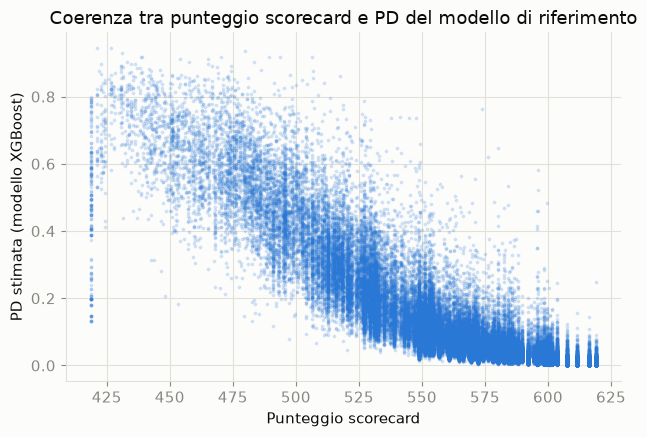

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(check['punteggio_scorecard'], check['PD'], s=3, alpha=0.15, color=COLOR_SEQ)
ax.set_xlabel('Punteggio scorecard')
ax.set_ylabel('PD stimata (modello XGBoost)')
ax.set_title('Coerenza tra punteggio scorecard e PD del modello di riferimento')
plt.tight_layout()
plt.show()

La forte correlazione negativa conferma che la scorecard, pur usando solo 5 variabili con un
encoding lineare (WOE), ordina i clienti in modo coerente con il modello XGBoost molto più
complesso dei notebook precedenti — un buon segnale di validità, anche se non sostituisce una
validazione fuori campione formale (qui costruita sull'intero dataset, non su un test set separato,
per le ragioni spiegate in §6).

## 8. Esportazione

In [14]:
EXCEL_PATH = PROJECT_ROOT / 'excel' / 'scorecard_data.xlsx'
scorecard_table.to_excel(EXCEL_PATH, index=False, sheet_name='scorecard')
print(f"Salvato: {EXCEL_PATH.relative_to(PROJECT_ROOT).as_posix()}  ({len(scorecard_table)} righe)")

Salvato: excel/scorecard_data.xlsx  (27 righe)


In [15]:
IV_PATH = PROJECT_ROOT / 'data' / 'processed' / 'iv_per_variabile.csv'
iv_summary.to_csv(IV_PATH, index=False)
print(f"Salvato: {IV_PATH.relative_to(PROJECT_ROOT).as_posix()}  ({len(iv_summary)} righe)")

Salvato: data/processed/iv_per_variabile.csv  (12 righe)


## Conclusioni

- Cinque variabili superano la soglia IV ≥ 0,1: `RevolvingUtilizationOfUnsecuredLines` e le tre
  colonne di ritardo pagamenti (tutte "sospette", IV > 0,5: coerenti con i notebook precedenti, ma per
  `NumberOfTimes90DaysLate` non è chiaro se il conteggio preceda il periodo del target, si veda §4) e `age` (IV media, 0,26).
- Tutte le altre variabili, incluso `DebtRatio`, non superano la soglia — coerente con quanto già
  osservato nei notebook `02`, `03` e `04`.
- La scorecard a punti (base 600, PDO 20) ordina i clienti in modo fortemente coerente con il
  modello XGBoost di riferimento (correlazione punteggio-PD fortemente negativa), pur usando solo
  5 variabili con un encoding lineare interamente trasparente — il punto di forza principale di
  questo approccio rispetto a un modello ad albero: ogni punto del punteggio finale è tracciabile a
  una fascia precisa di una variabile precisa, utile in contesti dove la spiegabilità delle
  decisioni di credito è un requisito, non un'opzione.
- Output: `excel/scorecard_data.xlsx` (tabella punti per fascia, base del calcolatore
  `excel/scorecard_calcolatore.xlsx`, che aggiunge il foglio di calcolo del punteggio) e
  `data/processed/iv_per_variabile.csv` (IV per variabile, ordinata).